# CSE 438 - Assignment 01
## Group Information
| Field | Details |
|----------------------------|----------------------------------------------|
| **Group ID** | Group B |
| **Student 1 Name** | Nasrullah Kaisher Sijan |
| **Student 1 ID** | 2023-1-60-204 |
| **Student 2 Name** | G M MOTA-TAHRIN TAYEF |
| **Student 2 ID** | 2022-1-60-109 |
| **Student 3 Name** | Bushra Tahsin |
| **Student 3 ID** | 2023-3-60-129 |
| **Notebook Type** | DeepLabV3 Notebook |
| **Assignment 01 Best Acc** | Semantic Segmentation Model Benchmark-ing |
| **Dataset Name (Kaggle)** | /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset |
| **Dataset Source** | Pixel-wise Annotation for Clear and Contaminated Regions Segmentation in Wireless Capsule Endoscopy Images: Kvasir capsule endoscopy |
| **Dataset Source Link** | https://data.mendeley.com/datasets/vmxhn95j8z/3 |
| **Submission Date** | 14 July 2026 |

# DeepLabV3 -- Part 2 (Post-Training: Evaluation, Error Analysis, Reporting)

## Purpose of this notebook

This notebook **continues** the DeepLabV3-ResNet50 experiment carried out
in `nb1-deeplabv3.ipynb` ("Part 1"). Part 1 completed training in full --
**60 epochs**, well past the required 50-epoch floor -- and its checkpoints,
logs, config, and figures are all already saved to disk under
`deepLab-result2/results/deeplabv3/`.

Part 1's kernel crashed *after* training finished, before Task F (test-set
evaluation) and Task G (error analysis) could run. **This notebook does not
redo any of Part 1's work.** It never constructs an epoch loop, never calls
a training step, and never overwrites Part 1's checkpoints. Its only job is
to:

1. Load Part 1's completed output directory (read-only) and copy it,
   untouched, into a **new** output directory.
2. Load `best_model.pth` for **inference only** and restore its full state
   (weights, optimizer, scheduler, epoch, best mIoU, config) for the record.
3. Run everything that comes *after* training: Task F (quantitative test
   evaluation), Task G (qualitative + failure-mode error analysis), and
   final reporting -- writing every new artifact into the new output
   directory alongside the copied Part 1 artifacts.

This notebook is self-contained: opening only this file and running it top
to bottom is sufficient, provided Part 1's output directory
(`deepLab-result2/`) is available on disk (e.g. attached as a Kaggle input
dataset, or present locally).

---
# Section 1 — Imports

In [1]:
# ============================================================================
# IMPORTS
# ============================================================================
import json
import platform
import random
import shutil
import time
import warnings
from datetime import datetime
from pathlib import Path
from typing import Any, Optional, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

# OpenCV is used for image/mask I/O, consistent with the coding style
# established in Part 1.
import cv2
cv2.setNumThreads(0)  # avoid fighting with DataLoader's own worker processes

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

print("Imports complete.")
print(f"  torch version        : {torch.__version__}")
print(f"  torchvision version   : {torchvision.__version__}")
print(f"  albumentations version : {A.__version__}")

Imports complete.
  torch version        : 2.10.0+cu128
  torchvision version   : 0.25.0+cu128
  albumentations version : 2.0.8


---
# Section 2 — Locate Previous Output Directory

Part 1's completed output tree looks like this:

```
deepLab-result2/
    __results___files/
    results/
        deeplabv3/
            checkpoints/   (best_model.pth, last_model.pth, checkpoint_epoch010...060.pth)
            config/
            figures/
            logs/
            reports/
```

`PREVIOUS_OUTPUT_ROOT` below is the only path that should need editing --
every other path in this notebook is derived from it or from
`PREPROCESSING_ROOT` (Section 5). A short list of likely locations is
checked automatically (local working directory, common Kaggle input mount
points); if none of them exist, edit `PREVIOUS_OUTPUT_ROOT` by hand and
re-run this cell.

In [2]:
# ============================================================================
# LOCATE deepLab-result2 (Part 1's completed output directory) -- READ ONLY
# ============================================================================
_PREVIOUS_OUTPUT_CANDIDATES = [
    Path("/kaggle/input/datasets/bushratahsin/deeplab-result2"),
    Path("/kaggle/input/datasets/bushratahsin/deeplab-result2/results/deeplabv3"),
    Path("/kaggle/input/datasets/bushratahsin/deeplab-result2/results"),
    Path("/kaggle/working/deepLab-result2"),
]

PREVIOUS_OUTPUT_ROOT = next((p for p in _PREVIOUS_OUTPUT_CANDIDATES if p.is_dir()), None)

if PREVIOUS_OUTPUT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate Part 1's output directory ('deepLab-result2'). "
        f"Checked: {[str(p) for p in _PREVIOUS_OUTPUT_CANDIDATES]}. "
        "Edit PREVIOUS_OUTPUT_ROOT above to point at it directly."
    )

PREVIOUS_RESULTS_DIR = PREVIOUS_OUTPUT_ROOT / "results" / "deeplabv3"
PREVIOUS_CHECKPOINT_DIR = PREVIOUS_RESULTS_DIR / "checkpoints"

print(f"PREVIOUS_OUTPUT_ROOT     : {PREVIOUS_OUTPUT_ROOT.resolve()}")
print(f"PREVIOUS_RESULTS_DIR     : {PREVIOUS_RESULTS_DIR.resolve()}")
print(f"PREVIOUS_CHECKPOINT_DIR  : {PREVIOUS_CHECKPOINT_DIR.resolve()}")

PREVIOUS_OUTPUT_ROOT     : /kaggle/input/datasets/bushratahsin/deeplab-result2
PREVIOUS_RESULTS_DIR     : /kaggle/input/datasets/bushratahsin/deeplab-result2/results/deeplabv3
PREVIOUS_CHECKPOINT_DIR  : /kaggle/input/datasets/bushratahsin/deeplab-result2/results/deeplabv3/checkpoints


In [3]:
# ============================================================================
# VERIFY TRAINING IS ALREADY COMPLETE -- this notebook must never proceed as
# if training still needs to run
# ============================================================================
class PreviousExperimentIncompleteError(RuntimeError):
    """Raised when Part 1's outputs are missing or training did not finish.
    This notebook must stop rather than silently fall back to training.
    """

_expected_checkpoint_names = (
    ["best_model.pth", "last_model.pth"]
    + [f"checkpoint_epoch{e:03d}" for e in range(10, 61, 10)]  # prefix match, timestamp varies
)

_found_checkpoint_files = sorted(p.name for p in PREVIOUS_CHECKPOINT_DIR.glob("*.pth")) \
    if PREVIOUS_CHECKPOINT_DIR.is_dir() else []

_checkpoint_check_rows = []
for expected in _expected_checkpoint_names:
    matched = any(name.startswith(expected) for name in _found_checkpoint_files)
    _checkpoint_check_rows.append({"expected_checkpoint": expected, "found": matched})
checkpoint_presence_df = pd.DataFrame(_checkpoint_check_rows)
display(checkpoint_presence_df)

_missing_checkpoints = checkpoint_presence_df.loc[~checkpoint_presence_df["found"], "expected_checkpoint"].tolist()
_training_history_path = PREVIOUS_RESULTS_DIR / "logs" / "training_history.csv"

if _missing_checkpoints or not _training_history_path.is_file():
    raise PreviousExperimentIncompleteError(
        f"Part 1's outputs look incomplete (missing checkpoints: {_missing_checkpoints}, "
        f"training_history.csv found={_training_history_path.is_file()}). This notebook "
        f"requires Part 1's training to have finished successfully."
    )

_previous_history_df = pd.read_csv(_training_history_path)
_epochs_completed_previously = len(_previous_history_df)
print(f"\nTraining already complete: {_epochs_completed_previously} epoch(s) recorded in "
      f"training_history.csv (all {len(checkpoint_presence_df)} expected checkpoint files found).")
print("This notebook will NOT train. Proceeding directly to checkpoint loading and evaluation.")

,expected_checkpoint,found
0,best_model.pth,True
1,last_model.pth,True
2,checkpoint_epoch010,True
3,checkpoint_epoch020,True
4,checkpoint_epoch030,True
5,checkpoint_epoch040,True
6,checkpoint_epoch050,True
7,checkpoint_epoch060,True



Training already complete: 63 epoch(s) recorded in training_history.csv (all 8 expected checkpoint files found).
This notebook will NOT train. Proceeding directly to checkpoint loading and evaluation.


---
# Section 3 — Create New Output Directory

All of this notebook's own outputs are written to a **new**, separate
directory (`deepLab-result2-part2/`) rather than into `deepLab-result2/`
directly -- so Part 1's outputs can never be overwritten, regardless of
what runs afterward.

In [4]:
# ============================================================================
# NEW OUTPUT DIRECTORY (this notebook's outputs; Part 1's are never touched)
# ============================================================================
NEW_OUTPUT_ROOT = Path("deepLab-result2-part2")
NEW_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print(f"NEW_OUTPUT_ROOT : {NEW_OUTPUT_ROOT.resolve()}")

NEW_OUTPUT_ROOT : /kaggle/working/deepLab-result2-part2


---
# Section 4 — Copy Previous Outputs

Every file Part 1 produced -- checkpoints, config, figures, logs, reports,
`__results___files/` -- is copied into `NEW_OUTPUT_ROOT` **before** any new
code runs, so nothing from Part 1 is ever lost even if this notebook is
re-run multiple times.

In [5]:
# ============================================================================
# COPY deepLab-result2/ -> deepLab-result2-part2/ (nothing from Part 1 is lost)
# ============================================================================
shutil.copytree(PREVIOUS_OUTPUT_ROOT, NEW_OUTPUT_ROOT, dirs_exist_ok=True)

# This notebook's own working paths, now inside the NEW output directory.
# Same sub-tree layout Part 1 used, so every helper function below (copied
# from Part 1 for self-containment) writes to the same relative locations.
OUTPUT_DIR = NEW_OUTPUT_ROOT / "results" / "deeplabv3"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CONFIG_DIR = OUTPUT_DIR / "config"
FIGURES_DIR = OUTPUT_DIR / "figures"
LOGS_DIR = OUTPUT_DIR / "logs"
REPORTS_DIR = OUTPUT_DIR / "reports"
TABLES_DIR = OUTPUT_DIR / "tables"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
for directory in (OUTPUT_DIR, CHECKPOINT_DIR, CONFIG_DIR, FIGURES_DIR, LOGS_DIR,
                   REPORTS_DIR, TABLES_DIR, PREDICTIONS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

_copied_subdirs = sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_dir())
print(f"Copied {PREVIOUS_OUTPUT_ROOT} -> {NEW_OUTPUT_ROOT}")
print(f"OUTPUT_DIR       : {OUTPUT_DIR.resolve()}")
print(f"Sub-directories present after copy: {_copied_subdirs}")
assert (CHECKPOINT_DIR / "best_model.pth").is_file(), "best_model.pth missing after copy -- copy failed."
print("\nVerified: best_model.pth is present in the copied checkpoint directory.")

Copied /kaggle/input/datasets/bushratahsin/deeplab-result2 -> deepLab-result2-part2
OUTPUT_DIR       : /kaggle/working/deepLab-result2-part2/results/deeplabv3
Sub-directories present after copy: ['checkpoints', 'config', 'figures', 'logs', 'predictions', 'reports', 'tables']

Verified: best_model.pth is present in the copied checkpoint directory.


---
# Section 5 — Reload Preprocessing Outputs

Exactly as in Part 1: this notebook reads its data split, class mapping,
and augmentation config directly from Notebook 0's frozen preprocessing
artifacts -- never re-derived -- so the test set evaluated here is
byte-for-byte identical to the one Part 1's `test_loader` would have used.

`PREPROCESSING_ROOT` is unrelated to `deepLab-result2`/`deepLab-result2-part2`
above: it is the original (read-only) Notebook-0 dataset input, not this
project's own output tree.

In [6]:
# ============================================================================
# CONFIGURATION -- the only path that should need editing (mirrors Part 1)
# ============================================================================
PREPROCESSING_ROOT = Path("/kaggle/input/datasets/bushratahsin/result5/results")

TRAIN_CSV_PATH = PREPROCESSING_ROOT / "splits" / "train.csv"
VALIDATION_CSV_PATH = PREPROCESSING_ROOT / "splits" / "validation.csv"
TEST_CSV_PATH = PREPROCESSING_ROOT / "splits" / "test.csv"
AUGMENTATION_CONFIG_PATH = PREPROCESSING_ROOT / "augmentation" / "augmentation_config.json"
PREPROCESSING_METADATA_PATH = PREPROCESSING_ROOT / "metadata" / "preprocessing_metadata.json"
LABEL_MAPPING_PATH = PREPROCESSING_ROOT / "metadata" / "label_mapping.json"

required_files: dict[str, Path] = {
    "test.csv": TEST_CSV_PATH,
    "augmentation_config.json": AUGMENTATION_CONFIG_PATH,
    "preprocessing_metadata.json": PREPROCESSING_METADATA_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
}
_missing_preprocessing = [name for name, path in required_files.items() if not path.is_file()]
if _missing_preprocessing:
    raise FileNotFoundError(
        f"Missing required Notebook 0 preprocessing artifacts under "
        f"'{PREPROCESSING_ROOT.resolve()}': {_missing_preprocessing}."
    )

with open(PREPROCESSING_METADATA_PATH) as f:
    preprocessing_metadata = json.load(f)
with open(LABEL_MAPPING_PATH) as f:
    label_mapping = json.load(f)
with open(AUGMENTATION_CONFIG_PATH) as f:
    augmentation_config = json.load(f)

test_df = pd.read_csv(TEST_CSV_PATH)

_dataset_info = preprocessing_metadata.get("dataset_information", {})
_class_info = preprocessing_metadata.get("class_information", {})
_randomness_info = preprocessing_metadata.get("randomness", {})

IMAGE_SIZE: tuple[int, int] = tuple(_dataset_info.get("image_size", (336, 336)))
NUM_CLASSES: int = len(_class_info.get("class_names_binary", [])) or 2
RANDOM_SEED: int = _randomness_info.get("random_seed", 42)

print("Preprocessing summary (loaded from Notebook 0, not recomputed):")
print(f"  Test samples      : {len(test_df)}")
print(f"  Image resolution  : {IMAGE_SIZE}")
print(f"  Number of classes : {NUM_CLASSES}")
print(f"  Random seed       : {RANDOM_SEED}")

Preprocessing summary (loaded from Notebook 0, not recomputed):
  Test samples      : 2411
  Image resolution  : (336, 336)
  Number of classes : 2
  Random seed       : 42


In [7]:
# ============================================================================
# REPRODUCIBILITY -- same seed Part 1 used
# ============================================================================
def set_global_seed(seed: int) -> None:
    """Seed Python's `random`, NumPy, and PyTorch (CPU and CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_global_seed(RANDOM_SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
NUM_WORKERS = 4
PIN_MEMORY = True

print(f"Reproducibility configured: RANDOM_SEED={RANDOM_SEED}")
print(f"Device: {DEVICE}")

Reproducibility configured: RANDOM_SEED=42
Device: cuda


---
# Section 6 — Dataset Class & Preprocessing Helpers (copied from Part 1)

This notebook is fully self-contained, so it cannot literally `import` code
from `nb1-deeplabv3.ipynb`. The functions and the `KvasirSegmentationDataset`
class below are copied **verbatim** from Part 1 -- same names, same logic,
same coding style -- so the test set produced here is guaranteed identical
to what Part 1 would have produced. Nothing here is redefined differently
or "improved"; only what evaluation actually needs is included (the
training-only pieces -- augmentation randomization aside, the training
loop, `EarlyStopping`, `History`, etc. -- are intentionally not reproduced,
since this notebook never trains).

In [8]:
# ============================================================================
# FIXED TRAINING CLASS CONVENTION (identical to Part 1)
# ============================================================================
FIXED_CLASS_MAPPING: dict[str, int] = {"Background": 0, "Clear": 0, "Contaminated": 1}
VALID_CLASS_INDICES = set(FIXED_CLASS_MAPPING.values())
CLASS_NAMES_BY_INDEX: list[str] = ["Clear", "Contaminated"]


class InvalidMaskError(ValueError):
    """Raised when a binary mask decodes to a pixel value outside {0, 1}."""


def load_image(path: Union[str, Path]) -> np.ndarray:
    """Load an image as an RGB uint8 array (OpenCV loads BGR by default)."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image at {path} (missing or corrupted).")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_binary_mask(path: Union[str, Path]) -> np.ndarray:
    """Load a binary GT mask as a single-channel grayscale array (raw pixel
    values, not yet remapped to class indices).
    """
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Could not read mask at {path} (missing or corrupted).")
    return mask


def mask_to_class_indices(raw_mask: np.ndarray, label_mapping: dict) -> np.ndarray:
    """Convert a raw grayscale mask into the fixed training convention
    (Clear=0, Contaminated=1), resolving the raw-pixel-value -> class-name
    mapping from Notebook 0's auto-detected `label_mapping.json`.
    """
    white_key = label_mapping["white_pixel_label"]
    black_key = "0" if white_key == "1" else "1"
    is_white = raw_mask >= 128
    class_indices = np.where(
        is_white, FIXED_CLASS_MAPPING[label_mapping[white_key]], FIXED_CLASS_MAPPING[label_mapping[black_key]]
    ).astype(np.int64)

    unique_values = set(np.unique(class_indices).tolist())
    if not unique_values.issubset(VALID_CLASS_INDICES):
        raise InvalidMaskError(f"Mask decoded to invalid class indices {unique_values - VALID_CLASS_INDICES}.")
    return class_indices


def overlay_mask(image: np.ndarray, class_mask: np.ndarray, alpha: float = 0.4) -> np.ndarray:
    """Tint contaminated pixels (class 1) red for visual inspection."""
    is_contaminated = (class_mask == FIXED_CLASS_MAPPING["Contaminated"])
    tint = np.zeros_like(image); tint[..., 0] = 255
    return np.where(is_contaminated[..., None], (image * (1 - alpha) + tint * alpha).astype(np.uint8), image)


print(f"Fixed training class convention: {FIXED_CLASS_MAPPING}")

Fixed training class convention: {'Background': 0, 'Clear': 0, 'Contaminated': 1}


In [9]:
# ============================================================================
# TRANSFORM PIPELINE -- reconstructed from augmentation_config.json,
# never redefined by hand (identical to Part 1)
# ============================================================================
class AugmentationConfigError(RuntimeError):
    """Raised when augmentation_config.json cannot be used to reconstruct
    an Albumentations pipeline.
    """


def build_transform_from_config(config: dict, pipeline_key: str) -> A.Compose:
    """Reconstruct an Albumentations pipeline directly from the loaded
    augmentation_config.json dict.
    """
    try:
        steps = []
        for step in sorted(config[pipeline_key], key=lambda s: s["order"]):
            transform_cls = getattr(A, step["name"], None) or (ToTensorV2 if step["name"] == "ToTensorV2" else None)
            if transform_cls is None:
                raise KeyError(f"Unknown transform '{step['name']}'")
            params = dict(step["parameters"])
            if step["probability"] is not None:
                params["p"] = step["probability"]
            steps.append(transform_cls(**params))
        return A.Compose(steps)
    except (KeyError, TypeError, ValueError) as exc:
        raise AugmentationConfigError(
            f"Could not reconstruct the '{pipeline_key}' pipeline from "
            f"{AUGMENTATION_CONFIG_PATH}: {exc}"
        ) from exc


# Only the deterministic eval pipeline is needed -- this notebook never trains.
eval_transform = build_transform_from_config(augmentation_config, "eval_pipeline")

_normalization = augmentation_config.get("normalization", {})
NORMALIZATION_MEAN: tuple[float, ...] = tuple(_normalization.get("mean", (0.485, 0.456, 0.406)))
NORMALIZATION_STD: tuple[float, ...] = tuple(_normalization.get("std", (0.229, 0.224, 0.225)))

print(f"eval_transform : {len(eval_transform.transforms)} steps (deterministic)")
print(f"Normalization  : mean={NORMALIZATION_MEAN}, std={NORMALIZATION_STD}")

eval_transform : 2 steps (deterministic)
Normalization  : mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)


In [10]:
# ============================================================================
# DATASET CLASS (identical to Part 1)
# ============================================================================
class KvasirSegmentationDataset(Dataset):
    """Self-contained PyTorch Dataset reading exclusively from a Notebook 0
    split CSV (train.csv / validation.csv / test.csv) -- never scans a
    folder, never recreates a split.
    """

    def __init__(self, csv_path: Union[str, Path], transform: A.Compose, label_mapping: dict) -> None:
        self.csv_path = Path(csv_path)
        if not self.csv_path.is_file():
            raise FileNotFoundError(f"Split CSV not found: {self.csv_path}")
        self.dataframe = pd.read_csv(self.csv_path)
        self.transform = transform
        self.label_mapping = label_mapping

    def __len__(self) -> int:
        return len(self.dataframe)

    def __getitem__(self, index: int) -> dict[str, Any]:
        row = self.dataframe.iloc[index]
        image = load_image(row["image_path"])
        raw_mask = load_binary_mask(row["binary_mask_path"])
        class_mask = mask_to_class_indices(raw_mask, self.label_mapping)

        transformed = self.transform(image=image, mask=class_mask)
        mask_out = transformed["mask"]

        return {
            "image": transformed["image"],
            "mask": mask_out.long() if torch.is_tensor(mask_out) else torch.from_numpy(mask_out).long(),
            "image_filename": row["image_filename"],
            "contaminated_percent": float(row["contaminated_percent"]),
            "cleanliness_label": str(row["cleanliness_label"]),
        }


def denormalize_image(image_tensor: torch.Tensor) -> np.ndarray:
    """Invert the Normalize step to recover a displayable uint8 RGB array."""
    mean = torch.tensor(NORMALIZATION_MEAN).view(3, 1, 1)
    std = torch.tensor(NORMALIZATION_STD).view(3, 1, 1)
    denorm = (image_tensor * std + mean).clamp(0, 1)
    return (denorm.permute(1, 2, 0).numpy() * 255).astype(np.uint8)


print("KvasirSegmentationDataset and denormalize_image defined.")

KvasirSegmentationDataset and denormalize_image defined.


---
# Section 7 — DeepLabV3 Model Definition (copied from Part 1)

Identical architecture-construction function as Part 1, so the checkpoint's
`state_dict` loads into a structurally identical model. This cell only
*constructs* the architecture (COCO-pretrained backbone, replaced
classifier heads) -- the actual trained weights are loaded from
`best_model.pth` in Section 8, not from these COCO-pretrained defaults.

In [11]:
def build_deeplabv3_model(num_classes: int) -> nn.Module:
    """Construct a DeepLabV3-ResNet50 model with COCO-pretrained weights and
    both classifier heads replaced to output `num_classes` channels.

    Note: the returned model's `forward()` returns a **dict**
    (`{"out": tensor}`, plus `{"aux": tensor}` when the auxiliary head is
    present) rather than a raw tensor -- see `extract_logits()` below.
    """
    weights = DeepLabV3_ResNet50_Weights.DEFAULT
    model = deeplabv3_resnet50(weights=weights, aux_loss=True)

    in_channels = model.classifier[4].in_channels
    model.classifier[4] = nn.Conv2d(in_channels, num_classes, kernel_size=1)

    if model.aux_classifier is not None:
        aux_in_channels = model.aux_classifier[4].in_channels
        model.aux_classifier[4] = nn.Conv2d(aux_in_channels, num_classes, kernel_size=1)

    return model


def summarize_model(model: nn.Module, model_name: str = "model") -> dict[str, Any]:
    """Report trainable/total parameter counts, estimated size, and device
    for any PyTorch model.
    """
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    size_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / (1024 ** 2)
    device = next(model.parameters()).device

    summary = {
        "model_name": model_name, "total_parameters": total_params,
        "trainable_parameters": trainable_params, "estimated_size_mb": size_mb, "device": str(device),
    }
    print(f"Model summary -- {model_name}:")
    print(f"  Total parameters      : {total_params:,}")
    print(f"  Trainable parameters   : {trainable_params:,}")
    print(f"  Estimated size           : {size_mb:.2f} MB")
    print(f"  Device                     : {device}")
    return summary


print("build_deeplabv3_model and summarize_model defined.")

build_deeplabv3_model and summarize_model defined.


---
# Section 8 — Load Best Checkpoint (Inference Only — Training Is NOT Resumed)

**This section never trains.** It loads `best_model.pth` into a freshly
constructed model for inference/evaluation purposes only. The checkpoint's
optimizer and scheduler state are also restored (for completeness / the
record), but neither optimizer nor scheduler is ever stepped anywhere in
this notebook -- there is no `for epoch in ...` loop, no `trainer.train()`,
no `optimizer.step()`, no `loss.backward()` for training anywhere below.

Reconstructing the optimizer/scheduler requires the exact training
hyperparameters, which are read from the checkpoint's own stored `config`
(falling back to the copied `training_configuration.json` if a checkpoint
predates that field) -- never re-guessed.

In [12]:
# ============================================================================
# LOAD THE BEST CHECKPOINT (weights + optimizer + scheduler + epoch + best
# metric + config) -- for inference and record-keeping ONLY
# ============================================================================
class CheckpointLoadError(RuntimeError):
    """Raised when the best checkpoint cannot be found, loaded, or verified."""


BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "best_model.pth"
if not BEST_CHECKPOINT_PATH.is_file():
    raise CheckpointLoadError(f"Best checkpoint not found at {BEST_CHECKPOINT_PATH}.")

checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location="cpu")

# --- Restore model weights ---------------------------------------------------
best_model = build_deeplabv3_model(NUM_CLASSES)
try:
    best_model.load_state_dict(checkpoint["model_state_dict"])
except RuntimeError as exc:
    raise CheckpointLoadError(f"Checkpoint does not match the current model architecture: {exc}") from exc
best_model = best_model.to(DEVICE)
best_model.eval()  # inference mode -- never switched to .train()

# --- Restore training metadata (epoch, best metric, config) -- record only --
CHECKPOINT_EPOCH: int = checkpoint["epoch"]
CHECKPOINT_BEST_METRIC: float = checkpoint["best_metric"]
RESTORED_TRAINING_CONFIG: dict[str, Any] = checkpoint.get("config") or json.loads(
    (CONFIG_DIR / "training_configuration.json").read_text()
)

# --- Restore optimizer + scheduler state (kept for the record; never stepped) ---
_restored_optimizer = torch.optim.AdamW(
    best_model.parameters(),
    lr=RESTORED_TRAINING_CONFIG["initial_learning_rate"],
    weight_decay=RESTORED_TRAINING_CONFIG["weight_decay"],
)
_optimizer_restored = False
if "optimizer_state_dict" in checkpoint:
    _restored_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    _optimizer_restored = True

_scheduler_restored = False
if "scheduler_state_dict" in checkpoint:
    _lr_params = RESTORED_TRAINING_CONFIG.get("lr_scheduler_params", {})
    _restored_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        _restored_optimizer,
        T_max=_lr_params.get("T_max", RESTORED_TRAINING_CONFIG.get("epochs", 60)),
        eta_min=_lr_params.get("eta_min", 0.0),
    )
    _restored_scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    _scheduler_restored = True

print(f"Best checkpoint loaded from {BEST_CHECKPOINT_PATH}")
print(f"  Checkpoint epoch                : {CHECKPOINT_EPOCH}")
print(f"  Checkpoint best_metric (val mIoU): {CHECKPOINT_BEST_METRIC:.4f}")
print(f"  Optimizer state restored        : {_optimizer_restored}")
print(f"  Scheduler state restored        : {_scheduler_restored}")
print("\nNo training will occur. best_model is in .eval() mode and is used "
      "for inference only for the remainder of this notebook.")

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 212MB/s]


Best checkpoint loaded from deepLab-result2-part2/results/deeplabv3/checkpoints/best_model.pth
  Checkpoint epoch                : 53
  Checkpoint best_metric (val mIoU): 0.8939
  Optimizer state restored        : True
  Scheduler state restored        : True

No training will occur. best_model is in .eval() mode and is used for inference only for the remainder of this notebook.


In [13]:
# ============================================================================
# CROSS-REFERENCE AGAINST THE COPIED TRAINING HISTORY (authoritative, on-disk)
# ============================================================================
history_df = pd.read_csv(LOGS_DIR / "training_history.csv")
epochs_completed = len(history_df)
best_row = history_df.loc[history_df["val_miou"].idxmax()]
epoch_times = history_df["epoch_time_seconds"].tolist()
total_training_time = float(history_df["epoch_time_seconds"].sum())

MIN_EPOCHS = 50
assert epochs_completed >= MIN_EPOCHS, (
    f"training_history.csv records only {epochs_completed} epoch(s), below the "
    f"required minimum of {MIN_EPOCHS} -- Part 1's training does not look complete."
)
assert abs(float(best_row["val_miou"]) - CHECKPOINT_BEST_METRIC) < 1e-3, (
    "Checkpoint's stored best_metric does not match training_history.csv -- possible "
    "inconsistency between Part 1's checkpointing and history logging."
)

best_model_summary = {
    "best_epoch": int(CHECKPOINT_EPOCH),
    "best_val_miou": float(best_row["val_miou"]),
    "best_val_dice": float(best_row["val_dice"]),
    "training_time_seconds": total_training_time,
    "checkpoint_path": str(BEST_CHECKPOINT_PATH),
    "device": str(DEVICE),
}

print(f"Training already complete: {epochs_completed} epochs (>= required minimum {MIN_EPOCHS}).")
print("Best model summary (from Part 1's training run):")
print(f"  Best Epoch              : {best_model_summary['best_epoch']}")
print(f"  Best Validation mIoU     : {best_model_summary['best_val_miou']:.4f}")
print(f"  Best Validation Dice      : {best_model_summary['best_val_dice']:.4f}")
print(f"  Total training time         : {total_training_time:.1f}s ({total_training_time / 60:.1f} min)")
print(f"  Checkpoint Path                : {best_model_summary['checkpoint_path']}")
print("\nCheckpoint best_metric verified consistent with training_history.csv.")

Training already complete: 63 epochs (>= required minimum 50).
Best model summary (from Part 1's training run):
  Best Epoch              : 53
  Best Validation mIoU     : 0.8939
  Best Validation Dice      : 0.9415
  Total training time         : 33563.7s (559.4 min)
  Checkpoint Path                : deepLab-result2-part2/results/deeplabv3/checkpoints/best_model.pth

Checkpoint best_metric verified consistent with training_history.csv.


---
# Section 9 — Load Test Dataset

`test.csv` is loaded exactly as Part 1 would load it -- the held-out split
never touched by training, validation-driven checkpoint selection, or
early stopping in Part 1.

In [14]:
# ============================================================================
# TEST DATASET AND DATALOADER
# ============================================================================
test_dataset = KvasirSegmentationDataset(TEST_CSV_PATH, eval_transform, label_mapping)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY and DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0, drop_last=False,
)

_sample = test_dataset[0]
print(f"Test dataset size : {len(test_dataset)}")
print(f"Test batches       : {len(test_loader)} (batch_size={test_loader.batch_size})")
print(f"Image tensor shape : {tuple(_sample['image'].shape)}")
print(f"Mask tensor shape   : {tuple(_sample['mask'].shape)}")

Test dataset size : 2411
Test batches       : 151 (batch_size=16)
Image tensor shape : (3, 336, 336)
Mask tensor shape   : (336, 336)


---
# Section 10 — Evaluation Metrics (copied from Part 1)

`compute_confusion_matrix`, `compute_segmentation_metrics`, and
`compute_detailed_metrics` are identical to Part 1's model-agnostic
implementations, so the numbers this notebook produces are directly
comparable to what Part 1's Task F/G sections would have produced had the
kernel not crashed.

In [15]:
# ============================================================================
# METRICS (model-agnostic; identical to Part 1)
# ============================================================================
def compute_confusion_matrix(preds: torch.Tensor, targets: torch.Tensor, num_classes: int) -> np.ndarray:
    """Accumulate a pixel-level confusion matrix `cm[true, pred]`."""
    preds_flat = preds.detach().cpu().numpy().reshape(-1).astype(np.int64)
    targets_flat = targets.detach().cpu().numpy().reshape(-1).astype(np.int64)
    indices = targets_flat * num_classes + preds_flat
    return np.bincount(indices, minlength=num_classes * num_classes).reshape(num_classes, num_classes)


def compute_segmentation_metrics(confusion_matrix: np.ndarray, epsilon: float = 1e-8) -> dict[str, float]:
    """Derive mIoU, Dice, and pixel accuracy from one pixel-level confusion matrix."""
    tp = np.diag(confusion_matrix).astype(np.float64)
    fp = confusion_matrix.sum(axis=0).astype(np.float64) - tp
    fn = confusion_matrix.sum(axis=1).astype(np.float64) - tp
    total = confusion_matrix.sum()

    iou = tp / (tp + fp + fn + epsilon)
    dice = (2 * tp) / (2 * tp + fp + fn + epsilon)
    recall = tp / (tp + fn + epsilon)

    return {
        "mean_iou": float(np.mean(iou)),
        "mean_dice": float(np.mean(dice)),
        "pixel_accuracy": float(tp.sum() / (total + epsilon)),
        "mean_pixel_accuracy": float(np.mean(recall)),
    }


def compute_detailed_metrics(
    confusion_matrix: np.ndarray, class_names: list[str], epsilon: float = 1e-8
) -> dict[str, Any]:
    """Compute the full required metric suite (mIoU, per-class IoU/Dice/
    Precision/Recall/F1/Pixel-Accuracy, overall and mean pixel accuracy)
    from one pixel-level confusion matrix.
    """
    num_classes = confusion_matrix.shape[0]
    total = confusion_matrix.sum()

    tp = np.diag(confusion_matrix).astype(np.float64)
    fp = confusion_matrix.sum(axis=0).astype(np.float64) - tp
    fn = confusion_matrix.sum(axis=1).astype(np.float64) - tp

    iou = tp / (tp + fp + fn + epsilon)
    dice = (2 * tp) / (2 * tp + fp + fn + epsilon)
    precision = tp / (tp + fp + epsilon)
    recall = tp / (tp + fn + epsilon)  # == per-class pixel accuracy
    f1 = (2 * precision * recall) / (precision + recall + epsilon)

    per_class = {
        class_names[c]: {
            "iou": float(iou[c]), "dice": float(dice[c]), "precision": float(precision[c]),
            "recall": float(recall[c]), "f1": float(f1[c]), "pixel_accuracy": float(recall[c]),
        }
        for c in range(num_classes)
    }
    return {
        "mean_iou": float(np.mean(iou)), "mean_dice": float(np.mean(dice)),
        "overall_pixel_accuracy": float(tp.sum() / (total + epsilon)),
        "mean_pixel_accuracy": float(np.mean(recall)),
        "per_class": per_class,
    }


def extract_logits(model_output: Any) -> torch.Tensor:
    """Unwrap torchvision's `{"out": tensor, ...}` segmentation output convention."""
    if isinstance(model_output, dict):
        return model_output["out"]
    return model_output


def decode_prediction(logits: torch.Tensor) -> torch.Tensor:
    """Argmax over the channel dimension to obtain integer class predictions."""
    return torch.argmax(logits, dim=1)


print("Metrics module ready: compute_confusion_matrix, compute_segmentation_metrics, "
      "compute_detailed_metrics, extract_logits, decode_prediction")

Metrics module ready: compute_confusion_matrix, compute_segmentation_metrics, compute_detailed_metrics, extract_logits, decode_prediction


---
# Section 11 — Task F: Testing & Quantitative Evaluation

The test set has not been touched by any process in Part 1 or this
notebook -- not training, not validation-driven checkpoint selection, not
early stopping, not learning-rate scheduling -- so the metrics below are an
honest estimate of generalization to unseen capsule endoscopy frames.

In [16]:
# ============================================================================
# RUN INFERENCE OVER THE ENTIRE TEST SET, COLLECTING PER-IMAGE + OVERALL METRICS
# ============================================================================
def compute_boundary_error_fraction(
    gt_mask: np.ndarray, pred_mask: np.ndarray, boundary_width_px: int = 5
) -> Optional[float]:
    """Fraction of misclassified pixels that fall within `boundary_width_px`
    of the ground-truth mask's boundary. Returns None if there are no error
    pixels at all.
    """
    gt_uint8 = (gt_mask.astype(np.uint8)) * 255
    kernel = np.ones((boundary_width_px, boundary_width_px), np.uint8)
    dilated = cv2.dilate(gt_uint8, kernel)
    eroded = cv2.erode(gt_uint8, kernel)
    boundary_band = (dilated > 0) & (eroded == 0)

    error_pixels = gt_mask != pred_mask
    n_errors = error_pixels.sum()
    if n_errors == 0:
        return None
    return float((error_pixels & boundary_band).sum() / n_errors)


def evaluate_test_set(
    model: nn.Module, loader: DataLoader, device: torch.device, num_classes: int,
) -> tuple[np.ndarray, pd.DataFrame, dict[str, float]]:
    """Run inference once over `loader`, returning: the aggregated
    confusion matrix, a per-image metrics DataFrame (for Section 13's error
    analysis), and inference-timing statistics.
    """
    model.eval()
    total_confusion_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    per_image_records: list[dict[str, Any]] = []
    total_inference_time = 0.0
    n_images = 0

    with torch.no_grad():
        for batch in tqdm(loader, desc="Test inference"):
            images = batch["image"].to(device)
            targets = batch["mask"].to(device)

            inference_start = time.perf_counter()
            logits = extract_logits(model(images))
            if device.type == "cuda":
                torch.cuda.synchronize()
            total_inference_time += time.perf_counter() - inference_start

            predictions = decode_prediction(logits)
            n_images += images.shape[0]

            for i in range(images.shape[0]):
                gt_np = targets[i].cpu().numpy()
                pred_np = predictions[i].cpu().numpy()

                sample_cm = compute_confusion_matrix(predictions[i], targets[i], num_classes)
                total_confusion_matrix += sample_cm
                sample_metrics = compute_segmentation_metrics(sample_cm)

                gt_contam_pixels = int((gt_np == FIXED_CLASS_MAPPING["Contaminated"]).sum())
                pred_contam_pixels = int((pred_np == FIXED_CLASS_MAPPING["Contaminated"]).sum())
                segmentation_ratio = (
                    pred_contam_pixels / gt_contam_pixels if gt_contam_pixels > 0 else None
                )

                per_image_records.append({
                    "image_filename": batch["image_filename"][i],
                    "iou": sample_metrics["mean_iou"],
                    "dice": sample_metrics["mean_dice"],
                    "pixel_accuracy": sample_metrics["pixel_accuracy"],
                    "contaminated_percent": float(batch["contaminated_percent"][i]),
                    "cleanliness_label": batch["cleanliness_label"][i],
                    "gt_contaminated_pixels": gt_contam_pixels,
                    "pred_contaminated_pixels": pred_contam_pixels,
                    "segmentation_ratio": segmentation_ratio,
                    "boundary_error_fraction": compute_boundary_error_fraction(gt_np, pred_np),
                })

    timing = {
        "total_inference_time_seconds": total_inference_time,
        "average_inference_time_seconds": total_inference_time / max(n_images, 1),
        "fps": n_images / max(total_inference_time, 1e-9),
        "n_images": n_images,
    }
    return total_confusion_matrix, pd.DataFrame(per_image_records), timing


test_confusion_matrix, per_image_metrics_df, inference_timing = evaluate_test_set(
    best_model, test_loader, DEVICE, NUM_CLASSES
)

print(f"Inference complete over {inference_timing['n_images']} test images.")
print(f"  Total inference time    : {inference_timing['total_inference_time_seconds']:.3f}s")
print(f"  Average time per image    : {inference_timing['average_inference_time_seconds'] * 1000:.2f} ms")
print(f"  Throughput (FPS)            : {inference_timing['fps']:.2f} images/sec")

Test inference:   0%|          | 0/151 [00:00<?, ?it/s]

Inference complete over 2411 test images.
  Total inference time    : 100.576s
  Average time per image    : 41.72 ms
  Throughput (FPS)            : 23.97 images/sec


In [17]:
# ============================================================================
# OVERALL + PER-CLASS METRICS TABLES
# ============================================================================
test_metrics = compute_detailed_metrics(test_confusion_matrix, CLASS_NAMES_BY_INDEX)

overall_metrics_table = pd.DataFrame([{
    "Mean IoU": test_metrics["mean_iou"],
    "Overall Pixel Accuracy": test_metrics["overall_pixel_accuracy"],
    "Mean Pixel Accuracy": test_metrics["mean_pixel_accuracy"],
    "Dice Coefficient": test_metrics["mean_dice"],
}])
print("Overall test-set metrics:")
display(overall_metrics_table)

per_class_metrics_table = pd.DataFrame([
    {"class": name, **stats} for name, stats in test_metrics["per_class"].items()
])
print("\nPer-class test-set metrics:")
display(per_class_metrics_table)

Overall test-set metrics:


,Mean IoU,Overall Pixel Accuracy,Mean Pixel Accuracy,Dice Coefficient
0,0.898051,0.98755,0.969059,0.943976



Per-class test-set metrics:


,class,iou,dice,precision,recall,f1,pixel_accuracy
0,Clear,0.986855,0.993384,0.996926,0.989868,0.993384,0.989868
1,Contaminated,0.809246,0.894567,0.846637,0.948250,0.894567,0.948250


---
# Section 12 — Confusion Matrix & Qualitative Predictions

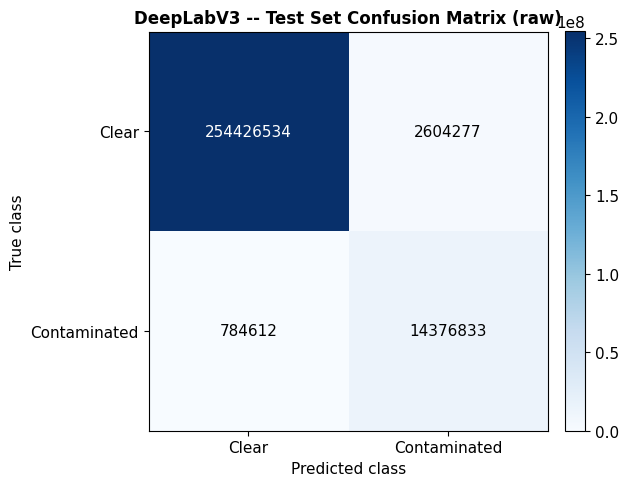

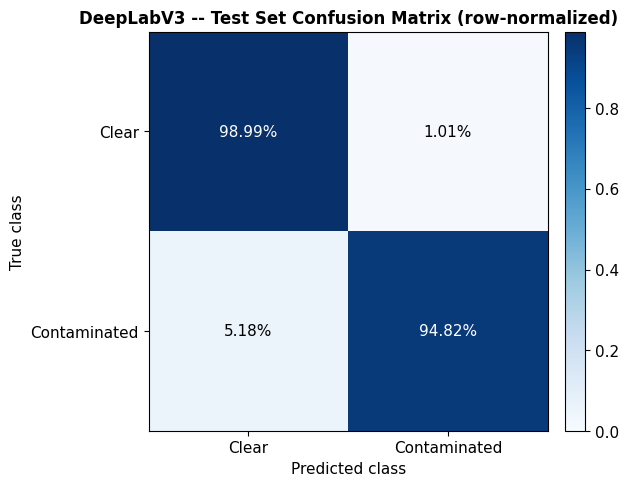

Saved -> deepLab-result2-part2/results/deeplabv3/figures/confusion_matrix.png
Saved -> deepLab-result2-part2/results/deeplabv3/figures/normalized_confusion_matrix.png


In [18]:
# ============================================================================
# PIXEL-LEVEL CONFUSION MATRIX
# ============================================================================
def normalize_confusion_matrix(cm: np.ndarray, epsilon: float = 1e-8) -> np.ndarray:
    """Row-normalize (recall-style) a confusion matrix."""
    return cm.astype(np.float64) / (cm.sum(axis=1, keepdims=True) + epsilon)


def plot_confusion_matrix(
    cm: np.ndarray, class_names: list[str], normalize: bool, title: str, save_path: Path,
) -> None:
    """Render and save a publication-quality confusion-matrix heatmap."""
    display_matrix = normalize_confusion_matrix(cm) if normalize else cm
    fmt = ".2%" if normalize else "d"

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(display_matrix, cmap="Blues", vmin=0)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names)
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(title, fontweight="bold")

    threshold = display_matrix.max() / 2.0
    for i in range(display_matrix.shape[0]):
        for j in range(display_matrix.shape[1]):
            value = display_matrix[i, j]
            text = f"{value:{fmt}}" if normalize else f"{int(value)}"
            ax.text(j, i, text, ha="center", va="center",
                    color="white" if value > threshold else "black", fontsize=11)

    fig.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_confusion_matrix(
    test_confusion_matrix, CLASS_NAMES_BY_INDEX, normalize=False,
    title="DeepLabV3 -- Test Set Confusion Matrix (raw)",
    save_path=FIGURES_DIR / "confusion_matrix.png",
)
plot_confusion_matrix(
    test_confusion_matrix, CLASS_NAMES_BY_INDEX, normalize=True,
    title="DeepLabV3 -- Test Set Confusion Matrix (row-normalized)",
    save_path=FIGURES_DIR / "normalized_confusion_matrix.png",
)
print(f"Saved -> {FIGURES_DIR / 'confusion_matrix.png'}")
print(f"Saved -> {FIGURES_DIR / 'normalized_confusion_matrix.png'}")

In [19]:
# ============================================================================
# SHARED VISUALIZATION HELPER (reused by the qualitative check below and
# Section 13's worst/best-performing error analysis, to avoid duplicated code)
# ============================================================================
def get_sample_visualization_data(
    dataset: "KvasirSegmentationDataset", index: int, model: nn.Module, device: torch.device,
) -> dict[str, Any]:
    """Run inference on one dataset sample and return everything needed to
    visualize and quantify it: denormalized image, ground-truth mask,
    predicted mask, filename, and per-image IoU/Dice/pixel accuracy.
    """
    sample = dataset[index]
    model.eval()
    with torch.no_grad():
        logits = extract_logits(model(sample["image"].unsqueeze(0).to(device)))
    prediction = decode_prediction(logits).squeeze(0).cpu()
    ground_truth = sample["mask"]

    cm = compute_confusion_matrix(prediction, ground_truth, NUM_CLASSES)
    metrics = compute_segmentation_metrics(cm)

    return {
        "image": denormalize_image(sample["image"]),
        "ground_truth": ground_truth.numpy(),
        "prediction": prediction.numpy(),
        "filename": sample["image_filename"],
        "iou": metrics["mean_iou"], "dice": metrics["mean_dice"], "pixel_accuracy": metrics["pixel_accuracy"],
    }


def plot_prediction_grid(records: list[dict[str, Any]], title: str, save_path: Path) -> None:
    """Plot Image | Ground Truth | Prediction | Overlay for each record, one
    row per sample, annotated with filename and per-image metrics.
    """
    n = len(records)
    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
    if n == 1:
        axes = axes[None, :]
    col_titles = ["Original Image", "Ground Truth", "Predicted Mask", "Overlay (Prediction)"]

    for row, record in enumerate(records):
        overlay = overlay_mask(record["image"], record["prediction"])
        panels = [record["image"], record["ground_truth"], record["prediction"], overlay]
        cmaps = [None, "gray", "gray", None]
        for col, (panel, cmap) in enumerate(zip(panels, cmaps)):
            ax = axes[row, col]
            ax.imshow(panel, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
            if row == 0:
                ax.set_title(col_titles[col], fontsize=12)
            ax.axis("off")
        axes[row, 0].text(
            -0.05, 0.5,
            f"{record['filename']}\nIoU={record['iou']:.3f}\nDice={record['dice']:.3f}\n"
            f"PixelAcc={record['pixel_accuracy']:.3f}",
            transform=axes[row, 0].transAxes, fontsize=8, ha="right", va="center",
        )

    fig.suptitle(title, fontsize=15, y=1.0)
    fig.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


print("Shared visualization helpers ready: get_sample_visualization_data, plot_prediction_grid")

Shared visualization helpers ready: get_sample_visualization_data, plot_prediction_grid


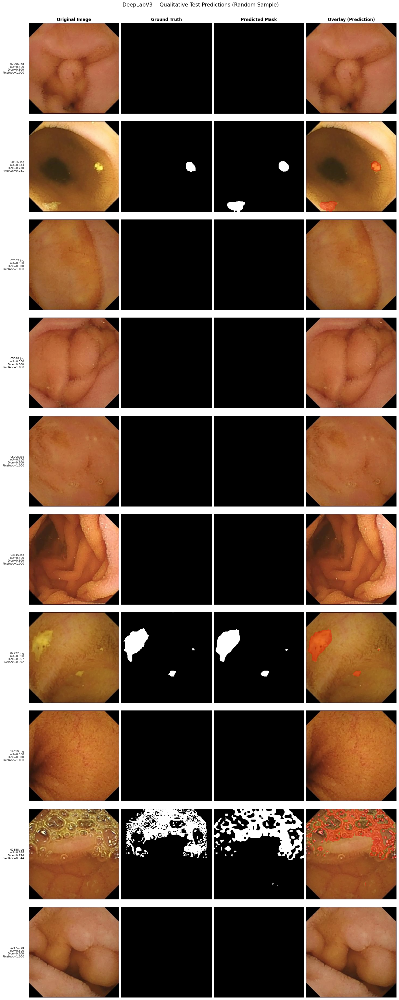

Saved -> deepLab-result2-part2/results/deeplabv3/figures/qualitative_predictions.png (10 samples)


In [20]:
# ============================================================================
# QUALITATIVE PREDICTION VISUALIZATION -- >= 10 random test images
# ============================================================================
N_QUALITATIVE_SAMPLES = 10
_qualitative_indices = random.sample(range(len(test_dataset)), min(N_QUALITATIVE_SAMPLES, len(test_dataset)))
qualitative_records = [
    get_sample_visualization_data(test_dataset, idx, best_model, DEVICE) for idx in _qualitative_indices
]

plot_prediction_grid(
    qualitative_records, "DeepLabV3 -- Qualitative Test Predictions (Random Sample)",
    FIGURES_DIR / "qualitative_predictions.png",
)
print(f"Saved -> {FIGURES_DIR / 'qualitative_predictions.png'} ({len(qualitative_records)} samples)")

In [21]:
# ============================================================================
# PREDICTION EXPORT -- save predicted masks for the visualization samples
# ============================================================================
for record in qualitative_records:
    stem = Path(record["filename"]).stem
    # Save as a visually inspectable 0/255 PNG (0=Clear, 255=Contaminated).
    pred_uint8 = (record["prediction"] * 255).astype(np.uint8)
    cv2.imwrite(str(PREDICTIONS_DIR / f"{stem}_pred.png"), pred_uint8)

print(f"Saved {len(qualitative_records)} prediction masks -> {PREDICTIONS_DIR}")

Saved 10 prediction masks -> deepLab-result2-part2/results/deeplabv3/predictions


---
# Section 13 — Metrics Export (CSV + JSON + Text Report)

In [22]:
# ============================================================================
# METRICS EXPORT
# ============================================================================
# --- test_metrics.csv (per-class + overall, one flat table) ----------------
_export_rows = per_class_metrics_table.to_dict(orient="records")
_export_rows.append({
    "class": "OVERALL", "iou": test_metrics["mean_iou"], "dice": test_metrics["mean_dice"],
    "precision": None, "recall": None, "f1": None,
    "pixel_accuracy": test_metrics["overall_pixel_accuracy"],
})
test_metrics_csv_path = TABLES_DIR / "test_metrics.csv"
pd.DataFrame(_export_rows).to_csv(test_metrics_csv_path, index=False)
print(f"Saved -> {test_metrics_csv_path}")

# --- metrics.json (fixed schema -- consumed by Notebook 4) -----------------
final_model_summary = summarize_model(best_model, model_name="DeepLabV3-ResNet50 (post-training, Part 2)")

metrics_json = {
    "model_name": RESTORED_TRAINING_CONFIG["model_name"],
    "backbone": RESTORED_TRAINING_CONFIG["backbone"],
    "epochs": epochs_completed,
    "best_epoch": best_model_summary["best_epoch"],
    "mIoU": test_metrics["mean_iou"],
    "Dice": test_metrics["mean_dice"],
    "Overall Pixel Accuracy": test_metrics["overall_pixel_accuracy"],
    "Mean Pixel Accuracy": test_metrics["mean_pixel_accuracy"],
    "Per-class IoU": {name: stats["iou"] for name, stats in test_metrics["per_class"].items()},
    "Per-class Dice": {name: stats["dice"] for name, stats in test_metrics["per_class"].items()},
    "Inference Time": inference_timing["total_inference_time_seconds"],
    "FPS": inference_timing["fps"],
    "Training Time": best_model_summary["training_time_seconds"],
    "Total Parameters": final_model_summary["total_parameters"],
}
METRICS_JSON_PATH = OUTPUT_DIR / "metrics.json"
with open(METRICS_JSON_PATH, "w") as f:
    json.dump(metrics_json, f, indent=2, default=str)
print(f"Saved -> {METRICS_JSON_PATH}")

# --- Test_Report.txt ---------------------------------------------------------
test_report_lines = [
    "=" * 78, "DEEPLABV3 -- TEST SET EVALUATION REPORT (Task F, Part 2)", "=" * 78, "",
    f"Test set size          : {len(test_dataset)}",
    f"Best epoch (checkpoint)  : {best_model_summary['best_epoch']}",
    "",
    "-" * 78, "Overall metrics", "-" * 78,
    overall_metrics_table.to_string(index=False),
    "",
    "-" * 78, "Per-class metrics", "-" * 78,
    per_class_metrics_table.to_string(index=False),
    "",
    "-" * 78, "Inference performance", "-" * 78,
    f"Total inference time     : {inference_timing['total_inference_time_seconds']:.3f}s",
    f"Average time per image     : {inference_timing['average_inference_time_seconds'] * 1000:.2f} ms",
    f"Throughput (FPS)              : {inference_timing['fps']:.2f} images/sec",
    "", "=" * 78,
]
test_report_text = "\n".join(test_report_lines)
(REPORTS_DIR / "Test_Report.txt").write_text(test_report_text)
print(f"Saved -> {REPORTS_DIR / 'Test_Report.txt'}")

Saved -> deepLab-result2-part2/results/deeplabv3/tables/test_metrics.csv
Model summary -- DeepLabV3-ResNet50 (post-training, Part 2):
  Total parameters      : 41,994,308
  Trainable parameters   : 41,994,308
  Estimated size           : 160.20 MB
  Device                     : cuda:0
Saved -> deepLab-result2-part2/results/deeplabv3/metrics.json
Saved -> deepLab-result2-part2/results/deeplabv3/reports/Test_Report.txt


---
# Section 14 — Task G: Error Analysis

Worst- and best-performing test images by IoU, color-coded error maps, and
statistics relating this run's actual errors back to the EDA's documented
17.12:1 pixel imbalance.

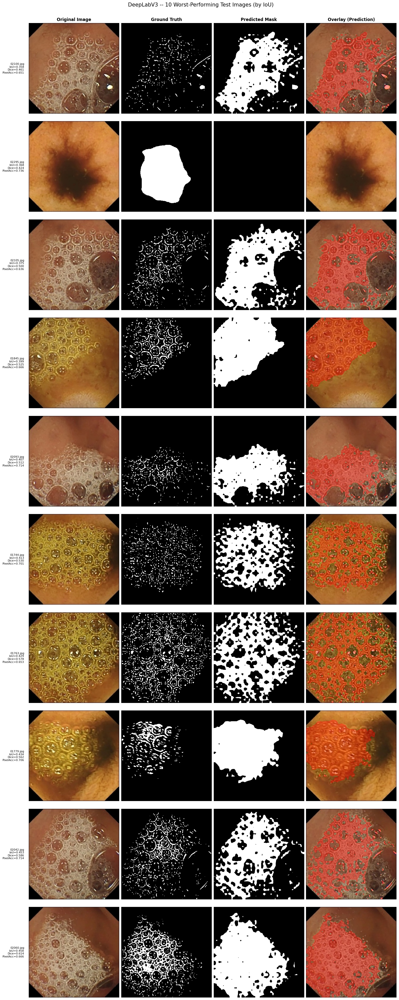

Saved -> deepLab-result2-part2/results/deeplabv3/figures/worst_performing_images.png


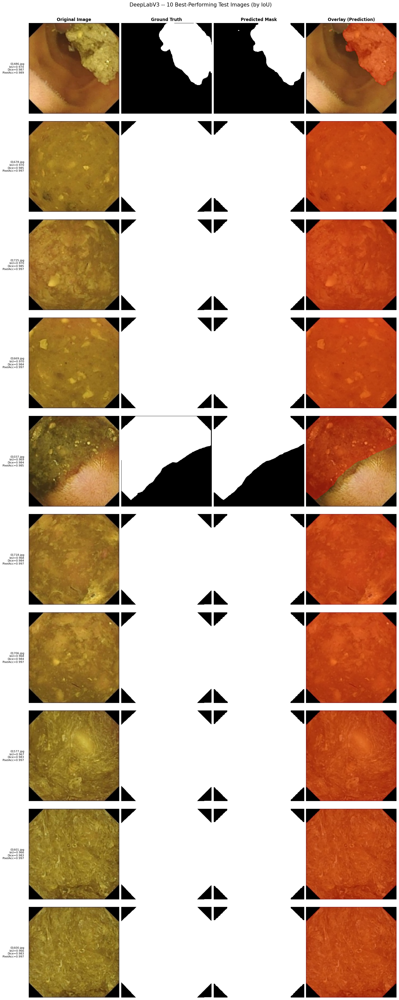

Saved -> deepLab-result2-part2/results/deeplabv3/figures/best_performing_images.png


In [23]:
# ============================================================================
# WORST- AND BEST-PERFORMING IMAGES
# ============================================================================
N_ERROR_ANALYSIS_SAMPLES = 10

worst_10_df = per_image_metrics_df.sort_values("iou", ascending=True).head(N_ERROR_ANALYSIS_SAMPLES)
worst_10_records = [get_sample_visualization_data(test_dataset, idx, best_model, DEVICE) for idx in worst_10_df.index]
plot_prediction_grid(
    worst_10_records, "DeepLabV3 -- 10 Worst-Performing Test Images (by IoU)",
    FIGURES_DIR / "worst_performing_images.png",
)
print(f"Saved -> {FIGURES_DIR / 'worst_performing_images.png'}")

best_10_df = per_image_metrics_df.sort_values("iou", ascending=False).head(N_ERROR_ANALYSIS_SAMPLES)
best_10_records = [get_sample_visualization_data(test_dataset, idx, best_model, DEVICE) for idx in best_10_df.index]
plot_prediction_grid(
    best_10_records, "DeepLabV3 -- 10 Best-Performing Test Images (by IoU)",
    FIGURES_DIR / "best_performing_images.png",
)
print(f"Saved -> {FIGURES_DIR / 'best_performing_images.png'}")

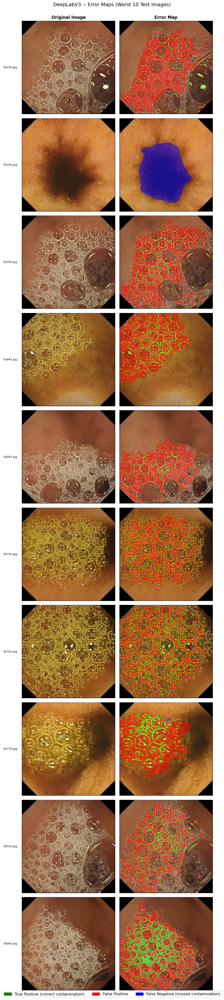

Saved -> deepLab-result2-part2/results/deeplabv3/figures/error_maps.png


In [24]:
# ============================================================================
# ERROR MAPS -- False Positives / False Negatives / Correct Predictions
# ============================================================================
def generate_error_map(image: np.ndarray, ground_truth: np.ndarray, prediction: np.ndarray, alpha: float = 0.5) -> np.ndarray:
    """Overlay a color-coded error map onto `image`: green = true positive,
    red = false positive, blue = false negative (missed contamination).
    """
    contaminated = FIXED_CLASS_MAPPING["Contaminated"]
    true_positive = (ground_truth == contaminated) & (prediction == contaminated)
    false_positive = (ground_truth != contaminated) & (prediction == contaminated)
    false_negative = (ground_truth == contaminated) & (prediction != contaminated)

    color_map = np.zeros_like(image)
    color_map[true_positive] = [0, 255, 0]
    color_map[false_positive] = [255, 0, 0]
    color_map[false_negative] = [0, 0, 255]

    highlighted = true_positive | false_positive | false_negative
    return np.where(highlighted[..., None], (image * (1 - alpha) + color_map * alpha).astype(np.uint8), image)


fig, axes = plt.subplots(N_ERROR_ANALYSIS_SAMPLES, 2, figsize=(9, 4 * N_ERROR_ANALYSIS_SAMPLES))
for row, record in enumerate(worst_10_records):
    error_map = generate_error_map(record["image"], record["ground_truth"], record["prediction"])
    axes[row, 0].imshow(record["image"]); axes[row, 0].set_title("Original Image" if row == 0 else ""); axes[row, 0].axis("off")
    axes[row, 1].imshow(error_map); axes[row, 1].set_title("Error Map" if row == 0 else ""); axes[row, 1].axis("off")
    axes[row, 0].text(-0.05, 0.5, record["filename"], transform=axes[row, 0].transAxes,
                       fontsize=8, ha="right", va="center")

legend_patches = [
    mpatches.Patch(color="green", label="True Positive (correct contamination)"),
    mpatches.Patch(color="red", label="False Positive"),
    mpatches.Patch(color="blue", label="False Negative (missed contamination)"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.005))
fig.suptitle("DeepLabV3 -- Error Maps (Worst 10 Test Images)", fontsize=14, y=1.0)
fig.tight_layout()
error_maps_path = FIGURES_DIR / "error_maps.png"
fig.savefig(error_maps_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved -> {error_maps_path}")

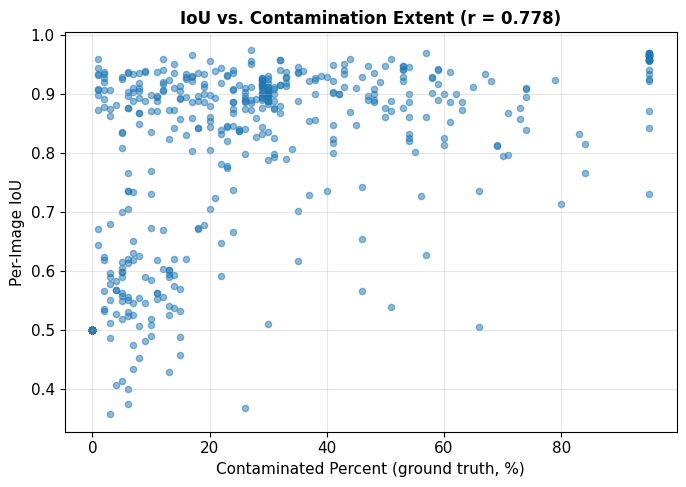

Failure mode analysis -- computed statistics:
  IoU vs. contamination-percent correlation : r = 0.778
  Mean fraction of errors within the GT boundary band : 0.543
  Mean predicted/GT contaminated-pixel ratio : 1.427 (over-segmentation)
  Mean IoU, smaller-than-median contamination regions : 0.758
  Mean IoU, larger-than-median contamination regions   : 0.881


In [25]:
# ============================================================================
# FAILURE MODE ANALYSIS -- grounded in this run's actual numbers
# ============================================================================
_valid_corr = per_image_metrics_df.dropna(subset=["contaminated_percent", "iou"])
iou_contam_correlation = float(np.corrcoef(_valid_corr["contaminated_percent"], _valid_corr["iou"])[0, 1])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(per_image_metrics_df["contaminated_percent"], per_image_metrics_df["iou"], alpha=0.5, s=20)
ax.set_xlabel("Contaminated Percent (ground truth, %)")
ax.set_ylabel("Per-Image IoU")
ax.set_title(f"IoU vs. Contamination Extent (r = {iou_contam_correlation:.3f})", fontweight="bold")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "iou_vs_contamination_percent.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

_boundary_fracs = per_image_metrics_df["boundary_error_fraction"].dropna()
mean_boundary_error_fraction = float(_boundary_fracs.mean()) if len(_boundary_fracs) > 0 else None

_valid_ratios = per_image_metrics_df["segmentation_ratio"].dropna()
mean_segmentation_ratio = float(_valid_ratios.mean()) if len(_valid_ratios) > 0 else None
segmentation_tendency = (
    "over-segmentation" if mean_segmentation_ratio and mean_segmentation_ratio > 1.05 else
    "under-segmentation" if mean_segmentation_ratio and mean_segmentation_ratio < 0.95 else
    "roughly balanced segmentation" if mean_segmentation_ratio else "undetermined (no GT-contaminated test images)"
)

_with_contam = per_image_metrics_df[per_image_metrics_df["gt_contaminated_pixels"] > 0]
if len(_with_contam) >= 4:
    _median_size = _with_contam["gt_contaminated_pixels"].median()
    _tiny_iou = float(_with_contam[_with_contam["gt_contaminated_pixels"] <= _median_size]["iou"].mean())
    _large_iou = float(_with_contam[_with_contam["gt_contaminated_pixels"] > _median_size]["iou"].mean())
else:
    _tiny_iou, _large_iou = None, None

print("Failure mode analysis -- computed statistics:")
print(f"  IoU vs. contamination-percent correlation : r = {iou_contam_correlation:.3f}")
print(f"  Mean fraction of errors within the GT boundary band : "
      f"{mean_boundary_error_fraction:.3f}" if mean_boundary_error_fraction is not None else "  N/A (no error pixels found)")
print(f"  Mean predicted/GT contaminated-pixel ratio : "
      f"{mean_segmentation_ratio:.3f} ({segmentation_tendency})" if mean_segmentation_ratio else "  N/A")
if _tiny_iou is not None:
    print(f"  Mean IoU, smaller-than-median contamination regions : {_tiny_iou:.3f}")
    print(f"  Mean IoU, larger-than-median contamination regions   : {_large_iou:.3f}")

In [26]:
# ============================================================================
# FAILURE MODE ANALYSIS -- narrative (generated from the statistics above)
# ============================================================================
_tiny_vs_large_line = (
    f"Splitting test images with any ground-truth contamination at the median "
    f"contaminated-pixel count, mean IoU was **{_tiny_iou:.3f}** for smaller-than-median "
    f"regions versus **{_large_iou:.3f}** for larger-than-median regions"
    + (", consistent with the EDA's severe pixel imbalance making tiny contamination regions "
       "harder to segment reliably." if _tiny_iou is not None and _tiny_iou < _large_iou
       else ", showing no clear size-driven gap in this run.")
) if _tiny_iou is not None else "Too few contaminated test images to reliably compare tiny vs. large regions."

failure_mode_markdown = f"""
**Missed contamination vs. pixel-level class imbalance.** The EDA
documented a 17.12:1 Clear:Contaminated pixel imbalance. This run's
correlation between per-image IoU and ground-truth `contaminated_percent`
is **r = {iou_contam_correlation:.3f}**{" (positive: images with more contamination tend to segment better, consistent with the imbalance making low-signal images harder)" if iou_contam_correlation > 0.1 else " (weak or negative: contamination extent alone does not strongly predict this model's per-image IoU in this run)"}.

**Boundary errors.** {"On average, **" + f"{mean_boundary_error_fraction:.1%}" + "** of a test image's misclassified pixels fall within a narrow band around the ground-truth contamination boundary." if mean_boundary_error_fraction is not None else "No error pixels were found across the sampled images to characterize."}

**Over- vs. under-segmentation.** The mean ratio of predicted to
ground-truth contaminated pixel count is
**{f'{mean_segmentation_ratio:.3f}' if mean_segmentation_ratio else 'undetermined'}**,
indicating **{segmentation_tendency}** in this run.

**Tiny vs. large contamination regions.** {_tiny_vs_large_line}
"""
display(Markdown(failure_mode_markdown))
(REPORTS_DIR / "Failure_Mode_Analysis.md").write_text(failure_mode_markdown)
print(f"Saved -> {REPORTS_DIR / 'Failure_Mode_Analysis.md'}")


**Missed contamination vs. pixel-level class imbalance.** The EDA
documented a 17.12:1 Clear:Contaminated pixel imbalance. This run's
correlation between per-image IoU and ground-truth `contaminated_percent`
is **r = 0.778** (positive: images with more contamination tend to segment better, consistent with the imbalance making low-signal images harder).

**Boundary errors.** On average, **54.3%** of a test image's misclassified pixels fall within a narrow band around the ground-truth contamination boundary.

**Over- vs. under-segmentation.** The mean ratio of predicted to
ground-truth contaminated pixel count is
**1.427**,
indicating **over-segmentation** in this run.

**Tiny vs. large contamination regions.** Splitting test images with any ground-truth contamination at the median contaminated-pixel count, mean IoU was **0.758** for smaller-than-median regions versus **0.881** for larger-than-median regions, consistent with the EDA's severe pixel imbalance making tiny contamination regions harder to segment reliably.


Saved -> deepLab-result2-part2/results/deeplabv3/reports/Failure_Mode_Analysis.md


---
# Section 15 — Final Reports & Export

In [27]:
# ============================================================================
# COMPUTATIONAL PERFORMANCE SUMMARY
# ============================================================================
_gpu_mem_allocated_mb = torch.cuda.memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else None
_gpu_mem_reserved_mb = torch.cuda.memory_reserved() / (1024 ** 2) if torch.cuda.is_available() else None

computational_performance_markdown = f"""
| Metric | Value |
|---|---|
| Total training time (Part 1) | {best_model_summary['training_time_seconds']:.1f}s ({best_model_summary['training_time_seconds']/60:.1f} min) |
| Average epoch time (Part 1) | {sum(epoch_times) / len(epoch_times):.1f}s |
| Epochs completed (Part 1) | {epochs_completed} |
| Inference speed (Part 2) | {inference_timing['fps']:.2f} images/sec ({inference_timing['average_inference_time_seconds']*1000:.1f} ms/image) |
| GPU memory allocated | {f'{_gpu_mem_allocated_mb:.1f} MB' if _gpu_mem_allocated_mb is not None else 'N/A (CPU)'} |
| GPU memory reserved | {f'{_gpu_mem_reserved_mb:.1f} MB' if _gpu_mem_reserved_mb is not None else 'N/A (CPU)'} |
| Model size | {final_model_summary['estimated_size_mb']:.2f} MB |
| Total parameters | {final_model_summary['total_parameters']:,} |
"""
display(Markdown(computational_performance_markdown))
(REPORTS_DIR / "Computational_Performance.md").write_text(computational_performance_markdown)
print(f"Saved -> {REPORTS_DIR / 'Computational_Performance.md'}")


| Metric | Value |
|---|---|
| Total training time (Part 1) | 33563.7s (559.4 min) |
| Average epoch time (Part 1) | 532.8s |
| Epochs completed (Part 1) | 63 |
| Inference speed (Part 2) | 23.97 images/sec (41.7 ms/image) |
| GPU memory allocated | 469.6 MB |
| GPU memory reserved | 2292.0 MB |
| Model size | 160.20 MB |
| Total parameters | 41,994,308 |


Saved -> deepLab-result2-part2/results/deeplabv3/reports/Computational_Performance.md


In [28]:
# ============================================================================
# NOTEBOOK METADATA (Output Structure)
# ============================================================================
notebook_metadata = {
    "notebook_name": "DeepLabV3_Part2.ipynb",
    "continues_from": str(PREVIOUS_OUTPUT_ROOT),
    "model_name": RESTORED_TRAINING_CONFIG["model_name"],
    "training_resumed": False,
    "sections_completed": [
        "1. Imports", "2. Locate Previous Output Directory", "3. Create New Output Directory",
        "4. Copy Previous Outputs", "5. Reload Preprocessing Outputs",
        "6. Dataset Class & Preprocessing Helpers", "7. Model Definition",
        "8. Load Best Checkpoint (inference only)", "9. Load Test Dataset",
        "10. Evaluation Metrics", "11. Task F -- Testing & Quantitative Evaluation",
        "12. Confusion Matrix & Qualitative Predictions", "13. Metrics Export",
        "14. Task G -- Error Analysis", "15. Final Reports & Export",
    ],
    "checkpoint_epoch": CHECKPOINT_EPOCH,
    "checkpoint_best_val_miou": CHECKPOINT_BEST_METRIC,
    "execution_date": datetime.now().isoformat(timespec="seconds"),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "random_seed": RANDOM_SEED,
    "device_used": str(DEVICE),
}
NOTEBOOK_METADATA_PATH = OUTPUT_DIR / "notebook_metadata_part2.json"
with open(NOTEBOOK_METADATA_PATH, "w") as f:
    json.dump(notebook_metadata, f, indent=2, default=str)
print(f"Saved -> {NOTEBOOK_METADATA_PATH}")

Saved -> deepLab-result2-part2/results/deeplabv3/notebook_metadata_part2.json


---
# Final Notebook Summary

In [29]:
final_summary_markdown = f"""
**DeepLabV3-ResNet50's Task F (testing & quantitative evaluation) and Task G
(error analysis) have been completed in this Part 2 notebook, continuing
directly from Part 1's completed training -- no training was re-run.**

- Part 1 trained for {epochs_completed} epochs (minimum 50 required), selecting
  the best checkpoint (epoch {best_model_summary['best_epoch']}) by validation mIoU
  ({best_model_summary['best_val_miou']:.4f}). This notebook loaded that
  checkpoint strictly for inference.
- **All required Task F metrics have been computed on the held-out test
  set**: mIoU **{test_metrics['mean_iou']:.3f}**, Dice
  **{test_metrics['mean_dice']:.3f}**, overall pixel accuracy
  **{test_metrics['overall_pixel_accuracy']:.3f}**, mean pixel accuracy
  **{test_metrics['mean_pixel_accuracy']:.3f}**, plus full per-class IoU,
  Dice, Precision, Recall, F1, and pixel accuracy, alongside raw and
  normalized pixel-level confusion matrices.
- **Task G error analysis** identified the model's worst- and
  best-performing test images, boundary-vs-interior error decomposition,
  over/under-segmentation tendency, and the IoU-vs-contamination-extent
  relationship.
- **Every artifact from Part 1 was preserved**, and every new artifact from
  this notebook was written alongside it, under
  `{NEW_OUTPUT_ROOT}/results/deeplabv3/` (checkpoints, config, figures,
  logs, predictions, reports, tables, `metrics.json`,
  `notebook_metadata_part2.json`).
"""
display(Markdown(final_summary_markdown))


**DeepLabV3-ResNet50's Task F (testing & quantitative evaluation) and Task G
(error analysis) have been completed in this Part 2 notebook, continuing
directly from Part 1's completed training -- no training was re-run.**

- Part 1 trained for 63 epochs (minimum 50 required), selecting
  the best checkpoint (epoch 53) by validation mIoU
  (0.8939). This notebook loaded that
  checkpoint strictly for inference.
- **All required Task F metrics have been computed on the held-out test
  set**: mIoU **0.898**, Dice
  **0.944**, overall pixel accuracy
  **0.988**, mean pixel accuracy
  **0.969**, plus full per-class IoU,
  Dice, Precision, Recall, F1, and pixel accuracy, alongside raw and
  normalized pixel-level confusion matrices.
- **Task G error analysis** identified the model's worst- and
  best-performing test images, boundary-vs-interior error decomposition,
  over/under-segmentation tendency, and the IoU-vs-contamination-extent
  relationship.
- **Every artifact from Part 1 was preserved**, and every new artifact from
  this notebook was written alongside it, under
  `deepLab-result2-part2/results/deeplabv3/` (checkpoints, config, figures,
  logs, predictions, reports, tables, `metrics.json`,
  `notebook_metadata_part2.json`).
